# Food Delivery Time Classification
Predict whether an order will arrive **Fast**, **On time** or **Late** using multiclass Logistic Regression, compared with a majority-class baseline.

**Pipeline:** load → create labels → EDA → preprocess (inside a sklearn Pipeline) → baseline → Logistic Regression → cross-validation → evaluation → interpretation → save model + demo.

In [6]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, os

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

## 1. Load and inspect

In [7]:
df = pd.read_csv("Food_Delivery_Times.csv")
print(df.shape)
display(df.head())
print(df.dtypes)
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())
display(df.describe().T)

(1000, 9)


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


Order_ID                    int64
Distance_km               float64
Weather                       str
Traffic_Level                 str
Time_of_Day                   str
Vehicle_Type                  str
Preparation_Time_min        int64
Courier_Experience_yrs    float64
Delivery_Time_min           int64
dtype: object

Missing values:
 Weather                   30
Traffic_Level             30
Time_of_Day               30
Courier_Experience_yrs    30
dtype: int64
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Order_ID,1000.0,500.500000,288.819436,1.00,250.750,500.50,750.2500,1000.00
Distance_km,1000.0,10.059970,5.696656,0.59,5.105,10.19,15.0175,19.99
Preparation_Time_min,1000.0,16.982000,7.204553,5.00,11.000,17.00,23.0000,29.00
Courier_Experience_yrs,970.0,4.579381,2.914394,0.00,2.000,5.00,7.0000,9.00
Delivery_Time_min,1000.0,56.732000,22.070915,8.00,41.000,55.50,71.0000,153.00


**Observations:** 1000 rows. Missing values appear in `Weather`, `Traffic_Level`, `Time_of_Day` and `Courier_Experience_yrs` (30 each, 3%). `Order_ID` is only an identifier, so we drop it.

## 2. Create the labels
Fixed cutoffs (chosen because they are easy to explain to a customer):

| Label | Delivery_Time_min |
|---|---|
| Fast | < 40 |
| On time | 40 to 60 (inclusive) |
| Late | > 60 |

`Delivery_Time_min` is **removed from the features immediately after the labels are made**. Keeping it would be data leakage (the model would see the answer).

In [8]:
LABELS = ["Fast", "On time", "Late"]

def make_label(minutes):
    return pd.cut(minutes, bins=[-np.inf, 39.999, 60, np.inf], labels=LABELS)

df["Delivery_Class"] = make_label(df["Delivery_Time_min"])
df_eda = df.copy()                       # keep minutes only for EDA plots
y = df["Delivery_Class"].astype(str)
X = df.drop(columns=["Order_ID", "Delivery_Time_min", "Delivery_Class"])   # leakage removed here

print("Features used:", list(X.columns))
print(y.value_counts().reindex(LABELS))
print((y.value_counts(normalize=True).reindex(LABELS)*100).round(1))

Features used: ['Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs']
Delivery_Class
Fast       240
On time    345
Late       415
Name: count, dtype: int64
Delivery_Class
Fast       24.0
On time    34.5
Late       41.5
Name: proportion, dtype: float64


## 3. Exploratory data analysis

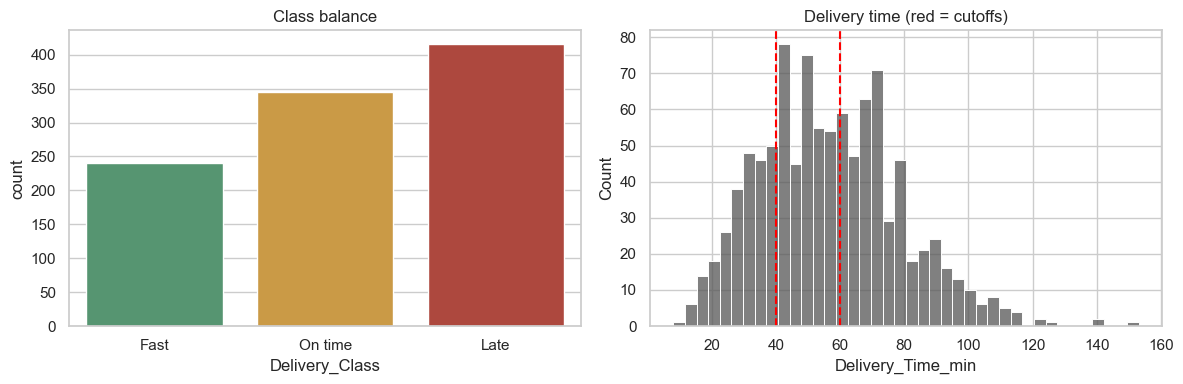

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="Delivery_Class", data=df, order=LABELS, ax=axes[0], palette=["#4c9f70", "#e0a030", "#c0392b"])
axes[0].set_title("Class balance")
sns.histplot(df["Delivery_Time_min"], bins=40, ax=axes[1], color="#555")
for v in (40, 60): axes[1].axvline(v, color="red", ls="--")
axes[1].set_title("Delivery time (red = cutoffs)")
plt.tight_layout(); plt.savefig("figures/01_class_balance.png", dpi=130); plt.show()

The classes are moderately imbalanced (Late is the largest, Fast the smallest), so we use **macro F1** besides accuracy. The long right tail of delivery time (up to 153 min) all falls into Late.

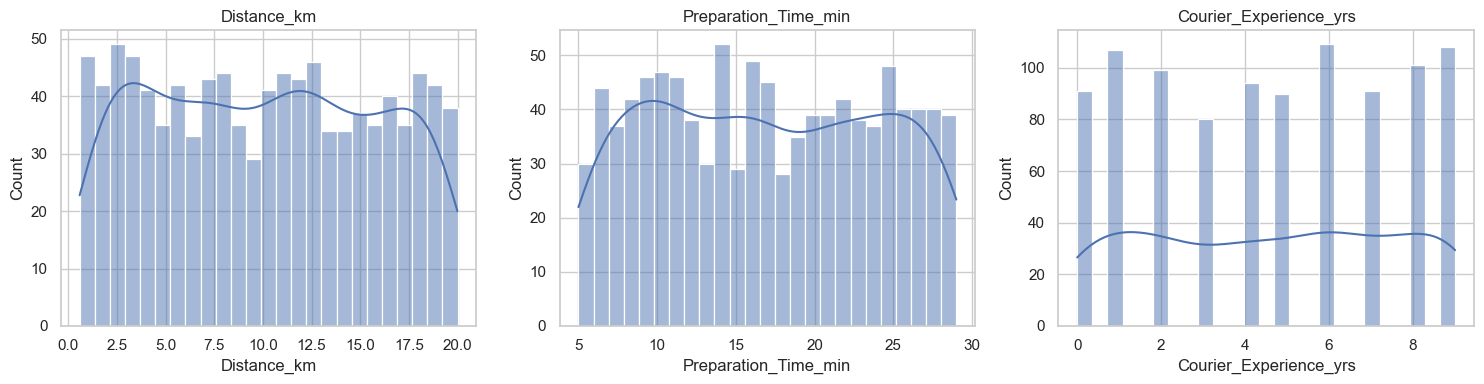

In [10]:
num_cols = ["Distance_km", "Preparation_Time_min", "Courier_Experience_yrs"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.histplot(df[c], bins=25, kde=True, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.savefig("figures/02_numeric_distributions.png", dpi=130); plt.show()

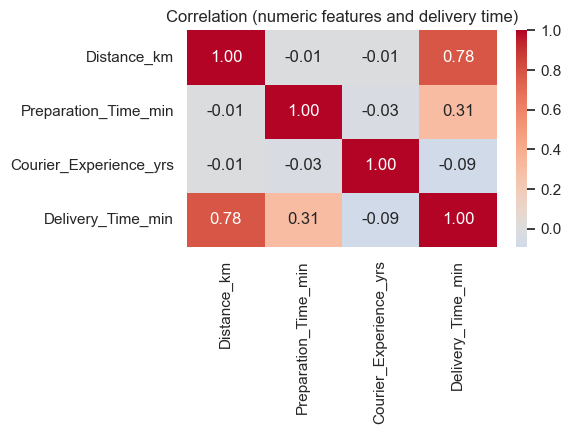

In [11]:
corr = df_eda[num_cols + ["Delivery_Time_min"]].corr()
plt.figure(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation (numeric features and delivery time)")
plt.tight_layout(); plt.savefig("figures/03_correlation_heatmap.png", dpi=130); plt.show()

Distance is by far the strongest numeric driver of delivery time (r ≈ 0.78), followed by preparation time (r ≈ 0.31); courier experience has a weak negative link (r ≈ -0.09). The three numeric features are almost uncorrelated with each other, so multicollinearity is not a concern.

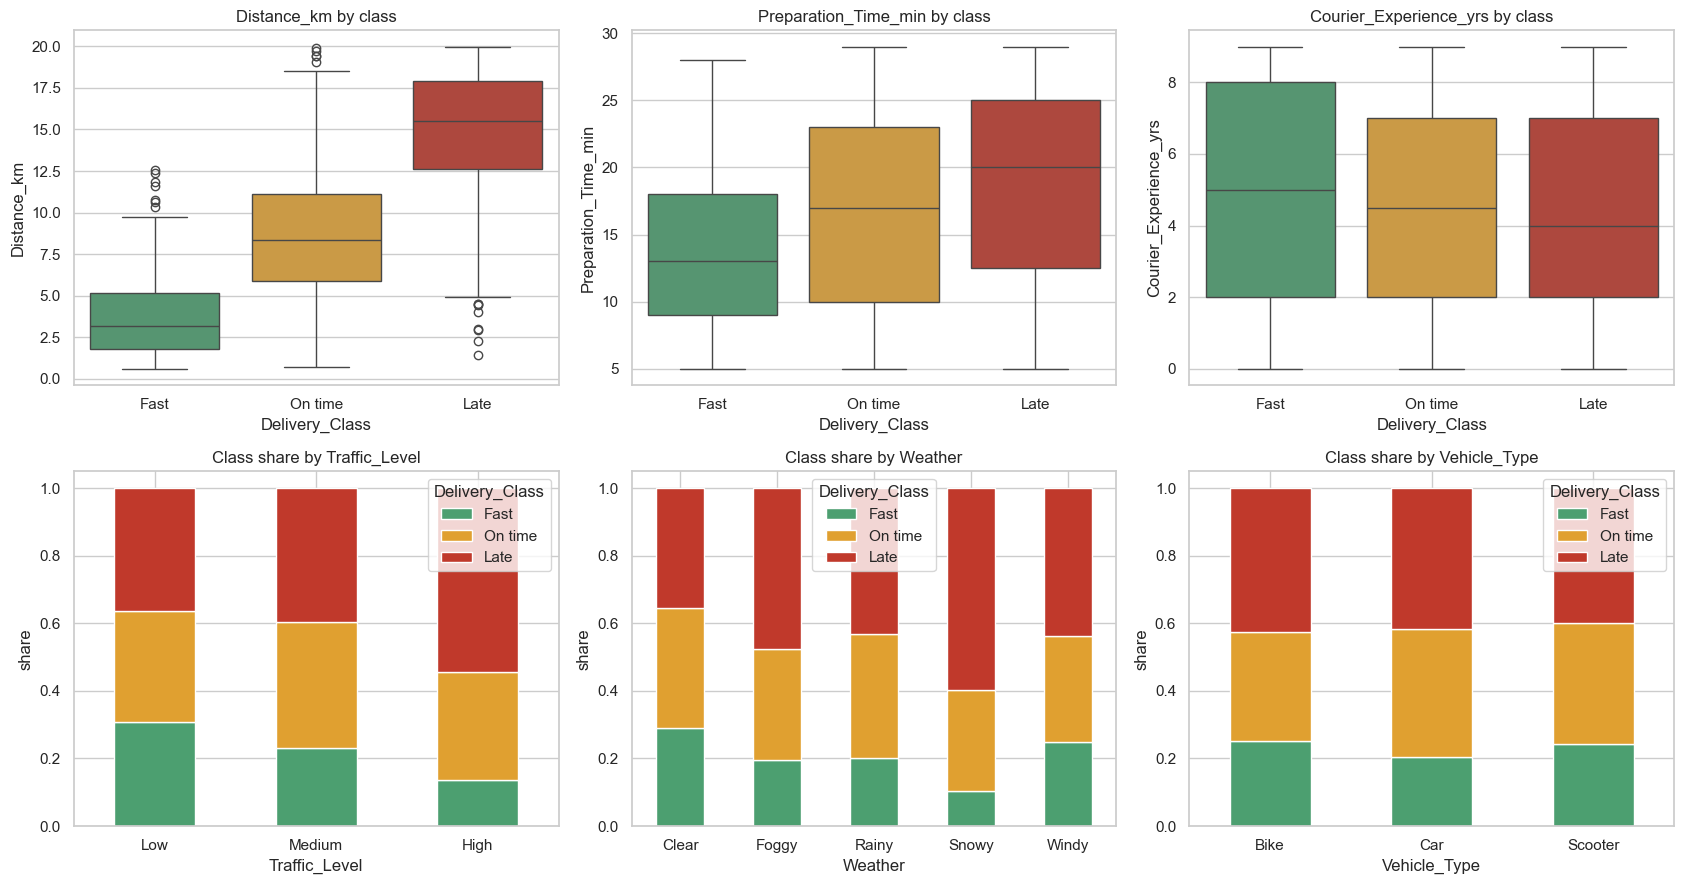

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
pal = {"Fast": "#4c9f70", "On time": "#e0a030", "Late": "#c0392b"}
for ax, c in zip(axes.ravel()[:3], num_cols):
    sns.boxplot(x="Delivery_Class", y=c, data=df, order=LABELS, palette=pal, ax=ax); ax.set_title(f"{c} by class")
order_map = {"Traffic_Level": ["Low", "Medium", "High"]}
for ax, c in zip(axes.ravel()[3:], ["Traffic_Level", "Weather", "Vehicle_Type"]):
    ct = pd.crosstab(df[c], df["Delivery_Class"], normalize="index")[LABELS]
    if c in order_map: ct = ct.reindex(order_map[c])
    ct.plot(kind="bar", stacked=True, ax=ax, color=[pal[l] for l in LABELS], rot=0)
    ax.set_title(f"Class share by {c}"); ax.set_ylabel("share")
plt.tight_layout(); plt.savefig("figures/04_features_vs_label.png", dpi=130); plt.show()

Clear patterns: longer distance, longer preparation time and heavier traffic push orders toward Late; Snowy (60% Late) and Foggy (48% Late) weather shift the mix toward Late far more than Clear weather (36% Late). These are confirmed quantitatively by the model coefficients in section 8.

## 4. Train/test split and preprocessing pipeline
We split **before** imputing/scaling and put all preprocessing in a `Pipeline`, so medians, modes and scaling statistics are learned from training data only (no leakage into the test set or into CV folds).

- Numeric: median imputation → standard scaling
- `Traffic_Level`: mode imputation → ordinal encoding (Low < Medium < High) → scaling
- `Weather`, `Time_of_Day`, `Vehicle_Type`: mode imputation → one-hot encoding

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

num_features  = ["Distance_km", "Preparation_Time_min", "Courier_Experience_yrs"]
ord_features  = ["Traffic_Level"]
nom_features  = ["Weather", "Time_of_Day", "Vehicle_Type"]

def build_preprocessor(scale=True):
    num = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    ordi = [("imp", SimpleImputer(strategy="most_frequent")),
            ("enc", OrdinalEncoder(categories=[["Low", "Medium", "High"]]))] + ([("sc", StandardScaler())] if scale else [])
    nom = [("imp", SimpleImputer(strategy="most_frequent")),
           ("enc", OneHotEncoder(handle_unknown="ignore"))]
    return ColumnTransformer([
        ("num", Pipeline(num), num_features),
        ("ord", Pipeline(ordi), ord_features),
        ("nom", Pipeline(nom), nom_features),
    ])

def make_model(clf, scale=True, k=None):
    steps = [("prep", build_preprocessor(scale))]
    if k: steps.append(("select", SelectKBest(f_classif, k=k)))
    steps.append(("clf", clf))
    return Pipeline(steps)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

(800, 7) (200, 7)


## 5. Baseline and Logistic Regression (5-fold cross-validation on the training set)

In [14]:
def cv_report(name, model):
    r = cross_validate(model, X_train, y_train, cv=cv,
                       scoring={"acc": "accuracy", "f1": "f1_macro"})
    return {"Model": name,
            "CV accuracy": r["test_acc"].mean(), "CV acc std": r["test_acc"].std(),
            "CV macro F1": r["test_f1"].mean(), "CV F1 std": r["test_f1"].std()}

candidates = {
    "Baseline (majority class)":          make_model(DummyClassifier(strategy="most_frequent")),
    "LogReg (unscaled)":                  make_model(LogisticRegression(max_iter=2000), scale=False),
    "LogReg (scaled)":                    make_model(LogisticRegression(max_iter=2000)),
    "LogReg (scaled, class_weight=bal.)": make_model(LogisticRegression(max_iter=2000, class_weight="balanced")),
}
cv_results = pd.DataFrame([cv_report(n, m) for n, m in candidates.items()]).round(3)
display(cv_results)

,Model,CV accuracy,CV acc std,CV macro F1,CV F1 std
0,Baseline (majority class),0.415,0.003,0.196,0.001
1,LogReg (unscaled),0.838,0.013,0.836,0.013
2,LogReg (scaled),0.835,0.017,0.834,0.017
3,"LogReg (scaled, class_weight=bal.)",0.820,0.011,0.820,0.012


Scaling matters little for accuracy here (lbfgs converges either way) but it makes the coefficients comparable across features, so we keep it. `class_weight='balanced'` is checked because Fast is the smallest class.

### Tune regularization strength C (cross-validated, optimising macro F1)

In [15]:
grid = GridSearchCV(
    make_model(LogisticRegression(max_iter=2000)),
    param_grid={"clf__C": [0.01, 0.1, 1, 10, 100]},
    cv=cv, scoring="f1_macro")
grid.fit(X_train, y_train)
print("Best C:", grid.best_params_["clf__C"], "| CV macro F1:", round(grid.best_score_, 3))
display(pd.DataFrame(grid.cv_results_)[["param_clf__C", "mean_test_score", "std_test_score"]].round(3))

Best C: 1 | CV macro F1: 0.834


,param_clf__C,mean_test_score,std_test_score
0,0.01,0.796,0.027
1,0.10,0.832,0.020
2,1.00,0.834,0.017
3,10.00,0.833,0.020
4,100.00,0.833,0.020


### Optional: feature selection with SelectKBest

In [16]:
n_total = make_model(LogisticRegression()).fit(X_train, y_train).named_steps["prep"].get_feature_names_out().shape[0]
rows = []
for k in [3, 5, 8, n_total]:
    m = make_model(LogisticRegression(max_iter=2000, C=grid.best_params_["clf__C"]), k=k)
    r = cross_validate(m, X_train, y_train, cv=cv, scoring="f1_macro")
    rows.append({"k features": k, "CV macro F1": r["test_score"].mean().round(3)})
display(pd.DataFrame(rows))

,k features,CV macro F1
0,3,0.809
1,5,0.839
2,8,0.840
3,16,0.834


Keeping 5 to 8 features scores marginally higher than keeping all 16, but the gain (about 0.005) is far smaller than the fold-to-fold standard deviation (about 0.017), so it is not a real improvement. We keep all features: simpler, and every coefficient stays interpretable. Using only 3 features clearly hurts.

## 6. Final model: evaluation on the held-out test set

In [17]:
best_C = grid.best_params_["clf__C"]
final_model = make_model(LogisticRegression(max_iter=2000, C=best_C))
final_model.fit(X_train, y_train)

baseline = make_model(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)

summary = []
for name, m in [("Baseline (majority class)", baseline), ("Logistic Regression", final_model)]:
    p = m.predict(X_test)
    summary.append({"Model": name, "Test accuracy": accuracy_score(y_test, p),
                    "Test macro F1": f1_score(y_test, p, average="macro")})
display(pd.DataFrame(summary).round(3))

pred = final_model.predict(X_test)
print(classification_report(y_test, pred, labels=LABELS, digits=3))

,Model,Test accuracy,Test macro F1
0,Baseline (majority class),0.415,0.196
1,Logistic Regression,0.840,0.844


              precision    recall  f1-score   support

        Fast      0.894     0.875     0.884        48
     On time      0.770     0.826     0.797        69
        Late      0.873     0.831     0.852        83

    accuracy                          0.840       200
   macro avg      0.846     0.844     0.844       200
weighted avg      0.843     0.840     0.841       200



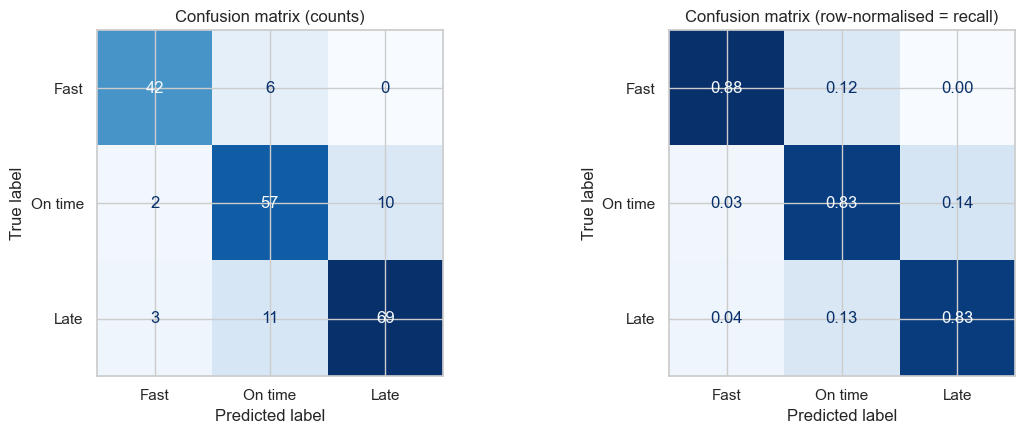

In [18]:
cm = confusion_matrix(y_test, pred, labels=LABELS)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=LABELS, normalize="true"),
                       display_labels=LABELS).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title("Confusion matrix (row-normalised = recall)")
plt.tight_layout(); plt.savefig("figures/05_confusion_matrix.png", dpi=130); plt.show()

### Cross-validation vs test (overfitting check)

,Train accuracy (CV folds),CV accuracy,Test accuracy,CV macro F1,Test macro F1
0,0.849,0.835,0.84,0.834,0.844


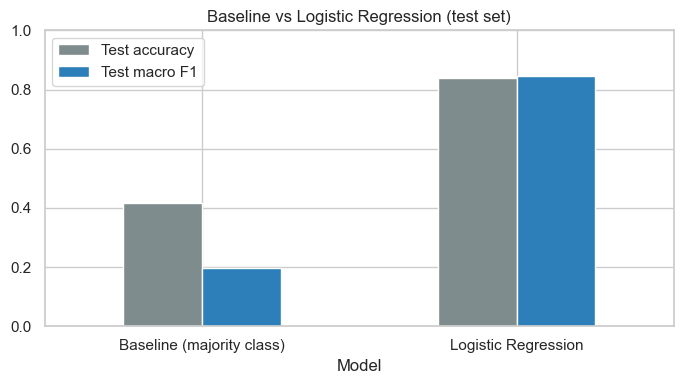

In [19]:
cv_final = cross_validate(final_model, X_train, y_train, cv=cv,
                          scoring={"acc": "accuracy", "f1": "f1_macro"}, return_train_score=True)
check = pd.DataFrame({
    "Train accuracy (CV folds)": [cv_final["train_acc"].mean()],
    "CV accuracy":               [cv_final["test_acc"].mean()],
    "Test accuracy":             [accuracy_score(y_test, pred)],
    "CV macro F1":               [cv_final["test_f1"].mean()],
    "Test macro F1":             [f1_score(y_test, pred, average="macro")],
}).round(3)
display(check)

fig, ax = plt.subplots(figsize=(7, 4))
res = pd.DataFrame(summary).set_index("Model")
res.plot(kind="bar", ax=ax, rot=0, color=["#7f8c8d", "#2c7fb8"]); ax.set_ylim(0, 1)
ax.set_title("Baseline vs Logistic Regression (test set)")
plt.tight_layout(); plt.savefig("figures/06_baseline_vs_model.png", dpi=130); plt.show()

## 7. Which classes get confused?

In [20]:
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = {(LABELS[i], LABELS[j]): off[i, j] for i in range(3) for j in range(3) if i != j}
pd.Series(pairs, name="count").sort_values(ascending=False).rename_axis(["true", "predicted"]).to_frame()

,,count
true,predicted,
Late,On time,11
On time,Late,10
Fast,On time,6
Late,Fast,3
On time,Fast,2
Fast,Late,0


As expected, nearly all errors are between **adjacent** classes (Fast ↔ On time, On time ↔ Late); a true Fast order is rarely predicted as Late and vice versa. The labels are cut from one continuous number, so orders near 40 or 60 minutes are inherently ambiguous.

## 8. Interpretation: what pushes an order toward Late?

,Fast,On time,Late
Distance_km,-4.231,0.501,3.730
Preparation_Time_min,-1.690,0.233,1.457
Weather_Snowy,-1.182,0.109,1.074
Traffic_Level,-0.897,0.123,0.774
Weather_Foggy,-0.415,0.033,0.382
Time_of_Day_Evening,-0.290,0.001,0.289
Vehicle_Type_Bike,0.046,-0.111,0.065
Vehicle_Type_Scooter,0.132,-0.107,-0.025
Vehicle_Type_Car,-0.182,0.216,-0.033
Weather_Windy,0.136,-0.096,-0.041


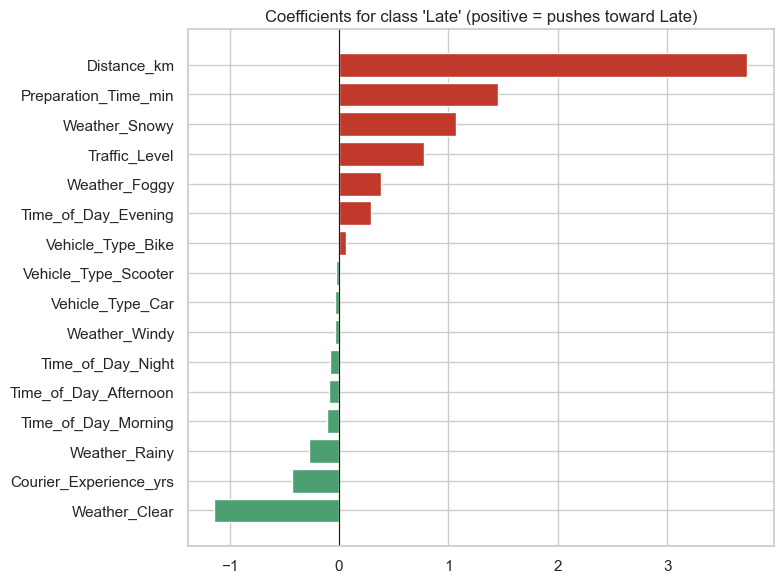

In [21]:
feat_names = final_model.named_steps["prep"].get_feature_names_out()
feat_names = [n.split("__")[1] for n in feat_names]
classes = final_model.named_steps["clf"].classes_
coefs = pd.DataFrame(final_model.named_steps["clf"].coef_, index=classes, columns=feat_names).T[LABELS]
display(coefs.sort_values("Late", ascending=False).round(3))

late = coefs["Late"].sort_values()
plt.figure(figsize=(8, 6))
plt.barh(late.index, late.values, color=["#c0392b" if v > 0 else "#4c9f70" for v in late.values])
plt.axvline(0, color="k", lw=.8)
plt.title("Coefficients for class 'Late' (positive = pushes toward Late)")
plt.tight_layout(); plt.savefig("figures/07_late_coefficients.png", dpi=130); plt.show()

Numeric features and traffic are standardised, so their coefficients are directly comparable (a +1 standard deviation change). One-hot weather/time/vehicle coefficients are read relative to the other categories of the same variable (e.g. Snowy 1.07 > Foggy 0.38 > Windy > Rainy > Clear -1.14). A positive coefficient for `Late` means higher odds of Late with everything else held fixed.

**Reading:** distance is the dominant driver, then preparation time, snowy weather, and traffic. Clear weather and a more experienced courier push away from Late. Vehicle type and time of day have near-zero coefficients (evening is slightly worse), i.e. they add little once distance, preparation, weather and traffic are known.

In [22]:
# Odds ratios for 'Late' (exp of coefficient) for easy wording in the report
odds = np.exp(coefs["Late"]).sort_values(ascending=False).round(2).rename("odds ratio (Late)")
display(odds.to_frame())

,odds ratio (Late)
Distance_km,41.70
Preparation_Time_min,4.29
Weather_Snowy,2.93
Traffic_Level,2.17
Weather_Foggy,1.47
Time_of_Day_Evening,1.34
Vehicle_Type_Bike,1.07
Vehicle_Type_Scooter,0.97
Vehicle_Type_Car,0.97
Weather_Windy,0.96


## 9. Save the model and demo

In [23]:
joblib.dump(final_model, "delivery_model.joblib")
print("Saved delivery_model.joblib")

Saved delivery_model.joblib


In [24]:
from predict import predict_delivery   # same function used by the web API (api.py)

demo = predict_delivery(distance_km=15.0, weather="Rainy", traffic_level="High",
                        time_of_day="Evening", vehicle_type="Bike",
                        preparation_time_min=25, courier_experience_yrs=1.0)
print(demo)   # probabilities are very confident because this dataset is almost noise-free (likely synthetic)

{'prediction': 'Late', 'probabilities': {'Fast': 0.0, 'Late': 0.995, 'On time': 0.005}}


In [25]:
demo2 = predict_delivery(distance_km=3.0, weather="Clear", traffic_level="Low",
                         time_of_day="Morning", vehicle_type="Scooter",
                         preparation_time_min=8, courier_experience_yrs=6.0)
print(demo2)

{'prediction': 'Fast', 'probabilities': {'Fast': 0.998, 'Late': 0.0, 'On time': 0.002}}


## 10. Limitations
- Small (1000 rows) and likely synthetic dataset: results will not generalise to a real platform.
- Labels depend on the chosen cutoffs (<40 / 40-60 / >60); other cutoffs change the class balance and the scores.
- Adjacent classes blur because the labels are cut from a continuous number; this is expected.
- Logistic Regression is linear; interactions (e.g. Rainy × High traffic) are not modelled.